# Models bencharmk

In this notebook we are benchmarking 3 models to determine which model is best for stock price prediction
After doing some research we decided to go with these 3 models:
 - ARIMA Model (with MA)
 - LSTM Model
 - GRU Model

The dataset used for our testing is AB.csv from 04-01-2010 -> 30-04-2025

In [16]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

Python: 3.12.8 (tags/v3.12.8:2dc476b, Dec  3 2024, 19:30:04) [MSC v.1942 64 bit (AMD64)]
PyTorch: 2.11.0+cu128
CUDA runtime: 12.8
GPU available: True


In [17]:
# %load_ext autoreload
# %autoreload 2
# Imports
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import numpy as np


# we need to add the project directory to import modules
import sys,os
from pathlib import Path
sys.path.insert(0, str(Path(os.getcwd()) / '..' / '..'))

from utils import split_dataset, train, get_features_target_from_dataset ,evaluate, plot_evaluation_result, plot_stock_graph
from src.prediction_model import ARIMAModel, GRUModel, LSTMModel
from enums import ValidationMetricEnum

In [18]:
# Load Dataset
csv_path = "BIAT.csv"

numeric_columns = ["ouverture", "haut", "bas", "cloture"]

data = pd.read_csv(
    "BIAT.csv",
    sep=";",
    decimal=",",
    dtype={column: float for column in numeric_columns},
    parse_dates=["date"],
		date_format="%d/%m/%Y",

)

print(data.dtypes)
data.head()

symbole                 str
date         datetime64[us]
ouverture           float64
haut                float64
bas                 float64
cloture             float64
volume                int64
dtype: object


,symbole,date,ouverture,haut,bas,cloture,volume
0,BIAT,2010-01-04,32.050,32.250,31.985,32.055,3188
1,BIAT,2010-01-05,32.150,34.005,32.150,34.005,10082
2,BIAT,2010-01-06,35.025,35.940,35.000,35.850,24088
3,BIAT,2010-01-07,35.900,36.500,35.000,35.745,21202
4,BIAT,2010-01-08,35.750,35.750,35.005,35.005,4910


In [19]:
df = data.copy()
df["log_return"] = np.log(
    df["cloture"] / df["cloture"].shift(1)
)

df["target_log_return"] = np.log(
    df["cloture"].shift(-1) / df["cloture"]
)

df["target_direction"] = (
    df["target_log_return"] > 0
).astype(int)

df.dropna(inplace=True)
df.head()

,symbole,date,ouverture,haut,bas,cloture,volume,log_return,target_log_return,target_direction
1,BIAT,2010-01-05,32.150,34.005,32.150,34.005,10082,0.059054,0.052836,1
2,BIAT,2010-01-06,35.025,35.940,35.000,35.850,24088,0.052836,-0.002933,0
3,BIAT,2010-01-07,35.900,36.500,35.000,35.745,21202,-0.002933,-0.020919,0
4,BIAT,2010-01-08,35.750,35.750,35.005,35.005,4910,-0.020919,0.027889,1
5,BIAT,2010-01-11,35.010,36.000,35.000,35.995,9048,0.027889,-0.001390,0


In [20]:
df_with_sma = data.copy()
df_with_sma['SMA_5'] = df_with_sma['cloture'].rolling(window=5).mean()
df_with_sma['SMA_20'] = df_with_sma['cloture'].rolling(window=20).mean()
df_with_sma['SMA_50'] = df_with_sma['cloture'].rolling(window=50).mean()

df_with_sma = df_with_sma.dropna()
df_with_sma.head()

,symbole,date,ouverture,haut,bas,cloture,volume,SMA_5,SMA_20,SMA_50
49,BIAT,2010-03-15,36.060,36.650,35.650,35.92,1742,35.941,36.4495,36.6050
50,BIAT,2010-03-16,35.755,36.595,35.755,35.87,6040,35.951,36.4430,36.6813
51,BIAT,2010-03-17,35.500,36.150,35.000,36.00,7040,36.020,36.4055,36.7212
52,BIAT,2010-03-18,36.600,36.600,36.250,36.25,1050,36.020,36.3805,36.7292
53,BIAT,2010-03-19,36.600,36.700,36.500,36.70,3876,36.148,36.3730,36.7483


In [21]:
train_dataset, test_dataset = split_dataset(dataset=df)
print(train_dataset.shape)
print(test_dataset.shape)

train_SMA, test_SMA = split_dataset(dataset=df_with_sma)
print(train_SMA.shape)
print(test_SMA.shape)

(3300, 10)
(825, 10)
(3263, 10)
(815, 10)


In [22]:
# prepare models and datasets
models_and_datasets = {"ARIMA": (ARIMAModel(), train_dataset, train_dataset), 
                       "GRU": (GRUModel(), train_dataset, test_dataset),
                      #  "GRU With SMA": (GRUModel(), train_SMA, test_SMA),
                      #  "GRU With cloture only": (GRUModel(), train_cloture, test_cloture),
                       "LSTM": (LSTMModel(), train_dataset, test_dataset),
                      #  "LSTM with SMA": (LSTMModel(), train_SMA, test_SMA),
                      #  "LSTM With cloture only": (LSTMModel(), train_cloture, test_cloture)
                       }

In [23]:
scalar_dict = train(models_and_datasets)

training ARIMA model ...
features shape: (26400,)


c:\Users\rezgu\OneDrive\Bureau\Stock-Price-Predictions-Model\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


training GRU model ...
features shape: (3299, 1, 8)
targets shape: (3299,)
Epoch 1/50 - loss: 0.012569 - device: cuda
Epoch 2/50 - loss: 0.011082 - device: cuda
Epoch 3/50 - loss: 0.002801 - device: cuda
Epoch 4/50 - loss: 0.001672 - device: cuda
Epoch 5/50 - loss: 0.001365 - device: cuda
Epoch 6/50 - loss: 0.001288 - device: cuda
Epoch 7/50 - loss: 0.001158 - device: cuda
Epoch 8/50 - loss: 0.001082 - device: cuda
Epoch 9/50 - loss: 0.001090 - device: cuda
Epoch 10/50 - loss: 0.001028 - device: cuda
Epoch 11/50 - loss: 0.001011 - device: cuda
Epoch 12/50 - loss: 0.001014 - device: cuda
Epoch 13/50 - loss: 0.000851 - device: cuda
Epoch 14/50 - loss: 0.000882 - device: cuda
Epoch 15/50 - loss: 0.000810 - device: cuda
Epoch 16/50 - loss: 0.000890 - device: cuda
Epoch 17/50 - loss: 0.000805 - device: cuda
Epoch 18/50 - loss: 0.000789 - device: cuda
Epoch 19/50 - loss: 0.000680 - device: cuda
Epoch 20/50 - loss: 0.000773 - device: cuda
Epoch 21/50 - loss: 0.000822 - device: cuda
Epoch 22/5

In [25]:
# one last effort to optimize arima
arima_dataset = data['cloture'].diff().dropna().values.reshape(-1,1)
print(arima_dataset)
print(arima_dataset.shape)

train_arima, test_arima = split_dataset(dataset=arima_dataset)
print(train_arima.shape)
print(test_arima.shape)

[[ 1.95 ]
 [ 1.845]
 [-0.105]
 ...
 [ 0.51 ]
 [ 4.5  ]
 [-5.   ]]
(4126, 1)
(3301, 1)
(825, 1)


In [26]:
optimized_arima_dict = {"ARIMA Optimized": (ARIMAModel(), train_arima, test_arima)}


In [27]:
arima_optimized_scaler = train(optimized_arima_dict)

training ARIMA Optimized model ...
features shape: (3301,)


In [28]:
# replace the old arima with the optimized
models_and_datasets["ARIMA"] = optimized_arima_dict["ARIMA Optimized"]
scalar_dict["ARIMA"] = arima_optimized_scaler["ARIMA Optimized"]

evaluating ARIMA model ...
number of days to predict: 825
prediction result shape: (825,)
test y dim before flattening:(825,)
predict y dim before flattening:(825,)
test y dim after flattening:(825,)
predict y dim after flattening:(825,)
evaluating GRU model ...
input shape: (822, 3, 8)
prediction result shape: (822, 1)
test y dim before flattening:(822,)
predict y dim before flattening:(822,)
test y dim after flattening:(822,)
predict y dim after flattening:(822,)
evaluating LSTM model ...
input shape: (822, 3, 8)
prediction result shape: (822, 1)
test y dim before flattening:(822,)
predict y dim before flattening:(822, 1)
test y dim after flattening:(822,)
predict y dim after flattening:(822,)


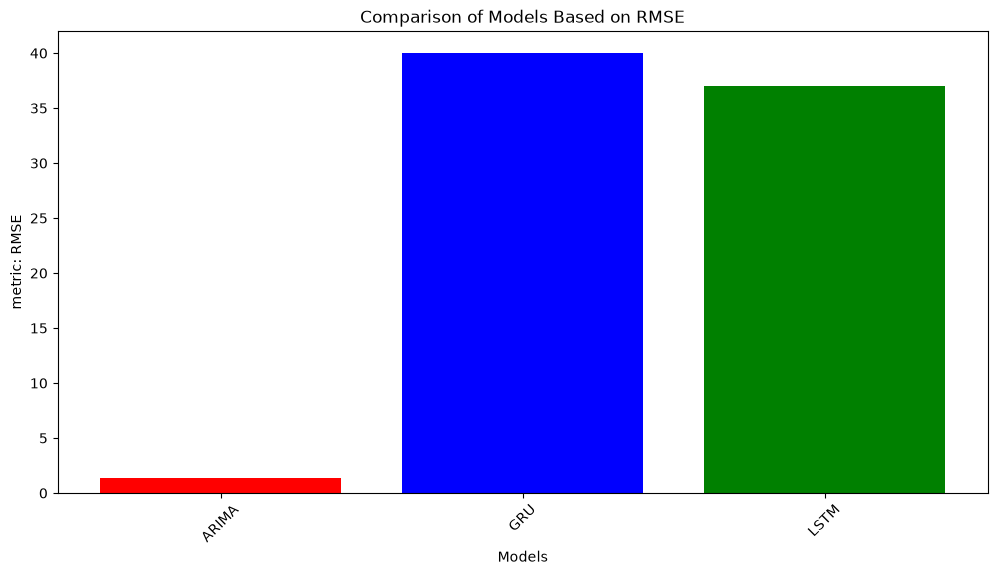

evaluating ARIMA model ...
number of days to predict: 825
prediction result shape: (825,)
test y dim before flattening:(825,)
predict y dim before flattening:(825,)
test y dim after flattening:(825,)
predict y dim after flattening:(825,)
evaluating GRU model ...
input shape: (822, 3, 8)
prediction result shape: (822, 1)
test y dim before flattening:(822,)
predict y dim before flattening:(822,)
test y dim after flattening:(822,)
predict y dim after flattening:(822,)
evaluating LSTM model ...
input shape: (822, 3, 8)
prediction result shape: (822, 1)
test y dim before flattening:(822,)
predict y dim before flattening:(822, 1)
test y dim after flattening:(822,)
predict y dim after flattening:(822,)


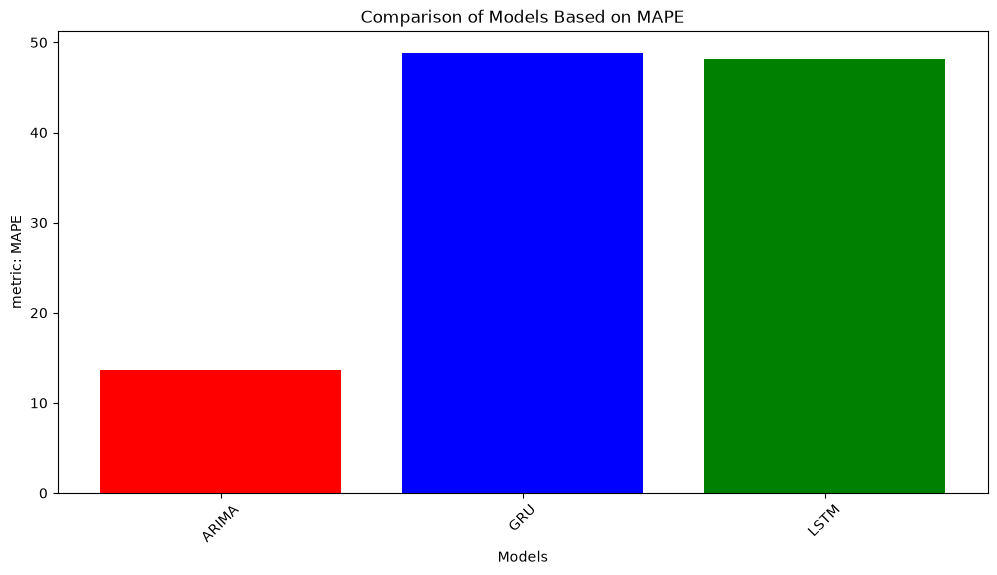

In [29]:
# rerun the evaluations
eval_result_rmse = evaluate(models_and_datasets, ValidationMetricEnum.RMSE, scalar_dict)
plot_evaluation_result(eval_result_rmse, "RMSE")

eval_result_mape = evaluate(models_and_datasets, ValidationMetricEnum.MAPE, scalar_dict)
plot_evaluation_result(eval_result_mape, "MAPE")

In [30]:
# eye test:
dates_for_df = test_dataset["date"][60:]
dates_for_sma = test_SMA["date"][60:]
dates_for_cloture = dates_for_df.copy()
dates_for_arima = test_dataset["date"]

models_and_dates = {"ARIMA": dates_for_arima, 
                       "GRU": dates_for_df,
                       "GRU With SMA": dates_for_sma,
                       "GRU With cloture only": dates_for_cloture,
                       "LSTM": dates_for_df,
                       "LSTM with SMA": dates_for_sma,
                       "LSTM With cloture only": dates_for_cloture}

plotting ARIMA model ...
number of days to predict: 825
prediction result shape: (825,)


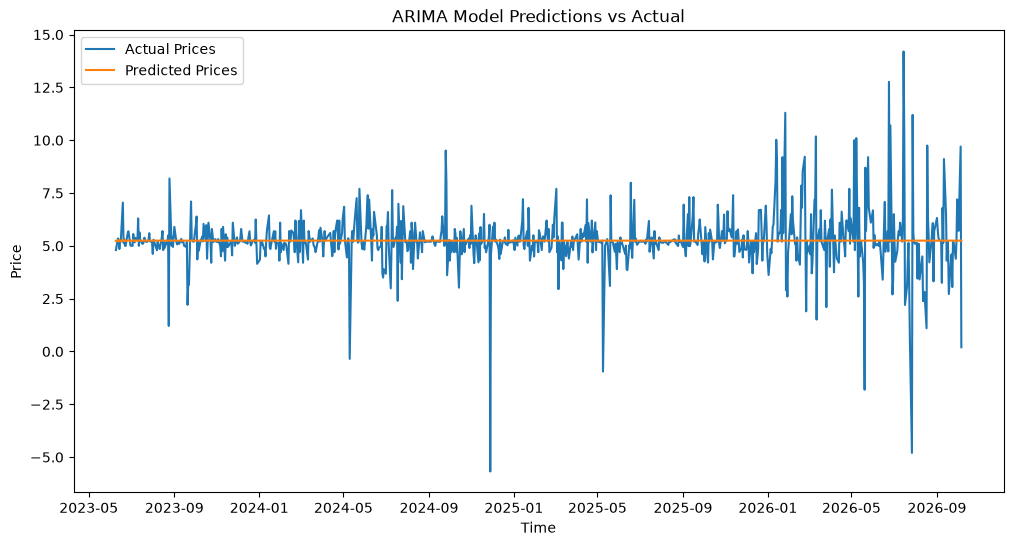

plotting GRU model ...
input shape: (822, 3, 8)
prediction result shape: (822, 1)


ValueError: x and y must have same first dimension, but have shapes (765,) and (822,)

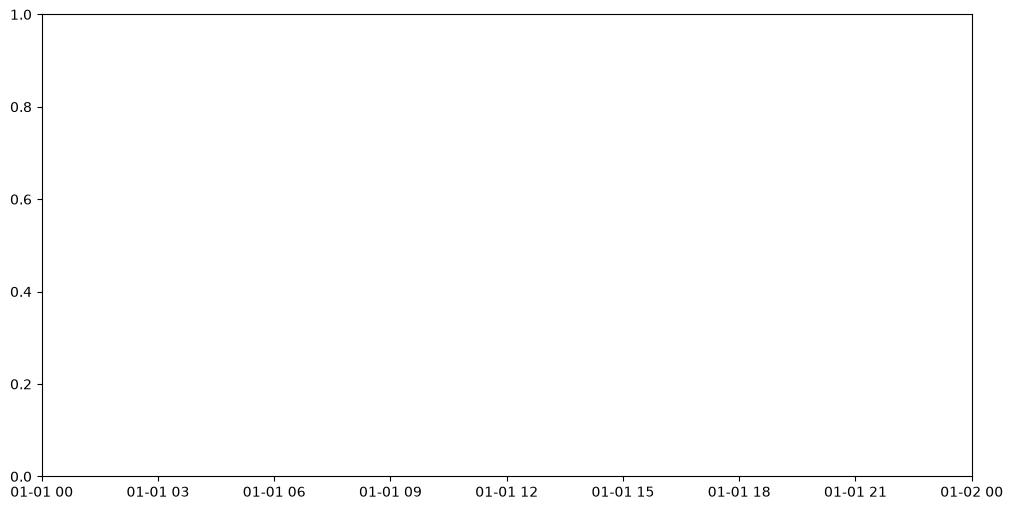

In [31]:
for key in models_and_dates.keys():
    print(f"plotting {key} model ...")
    dates = models_and_dates[key]
    model = models_and_datasets[key][0]
    test_df = models_and_datasets[key][2]
    scaler = scalar_dict[key]
    isArimaContext = isinstance(model, ARIMAModel)
    if isinstance(test_df, pd.DataFrame):
        test_features = test_df.loc[:, list(scaler.feature_names_in_)]
        closeColIdx = test_features.columns.get_loc('cloture')
    else:
        test_features = test_df
        closeColIdx = 0
    test_dataset_transformed = scaler.transform(test_features)
    scale = 1/scaler.scale_[closeColIdx]         
    x_test, y_test = get_features_target_from_dataset(test_dataset_transformed, closeColIdx=closeColIdx, isArimaContext=isArimaContext)
    y_pred = model.predict(x_test).flatten()
    y_test = y_test.flatten()
    y_pred = y_pred * scale
    y_test = y_test * scale
    plot_stock_graph(dates, y_test, y_pred, key)
    

